# Geotecnia II — 02: `geotools` tour

One short example per module of the `geotools` library (units: kN, m, kPa, degrees).
Every function is tested against textbook values in `tests/test_geotools.py`, which you can run with `pytest`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from geotools import bearing, classification, consolidation, earth_pressure, piles, slopes, stresses

## 1. Phase relationships and USCS classification

In [2]:
p = classification.phase_relations(Gs=2.70, e=0.65, w=0.22)
print({k: round(v, 3) for k, v in p.items()})
print("USCS:", classification.uscs(F200=8, F4=85, Cu=7, Cc=1.5, LL=30, PL=25),
      classification.uscs(F200=62, LL=48, PL=21))

{'e': 0.65, 'n': 0.394, 'w': 0.22, 'S': 0.914, 'gamma_d': 16.053, 'gamma': 19.584, 'gamma_sat': 19.917, 'gamma_sub': 10.107}
USCS: SW-SM CL


## 2. Effective stress profile

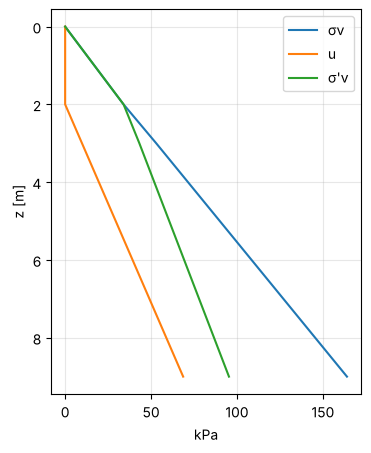

,z,sigma_v,u,sigma_v_eff
0,0.0,0.0,0.0,0.0
1,1.0,17.0,0.0,17.0
2,2.0,34.0,0.0,34.0
3,3.0,53.0,9.8,43.2
4,4.0,71.5,19.6,51.9
5,5.0,90.0,29.4,60.6
6,6.0,108.5,39.2,69.3
7,7.0,127.0,49.1,77.9
8,8.0,145.5,58.9,86.6
9,9.0,164.0,68.7,95.3


In [3]:
layers = [{"thickness": 3, "gamma": 17.0, "gamma_sat": 19.0},   # silty sand
          {"thickness": 6, "gamma": 18.0, "gamma_sat": 18.5}]   # soft clay
prof = stresses.stress_profile(layers, water_table=2.0, dz=1.0)
fig, ax = plt.subplots(figsize=(4, 5))
for col, lab in [("sigma_v", "σv"), ("u", "u"), ("sigma_v_eff", "σ'v")]:
    ax.plot(prof[col], prof["z"], label=lab)
ax.invert_yaxis(); ax.set_xlabel("kPa"); ax.set_ylabel("z [m]"); ax.legend(); ax.grid(alpha=.3)
plt.show()
prof.round(1)

## 3. Consolidation settlement of the clay under a 2 × 2 m footing (q = 150 kPa, Df = 1 m)

In [4]:
z_mid = 3 + 3                       # middle of the clay layer
sigma0 = stresses.vertical_stress(layers, z_mid, water_table=2.0)[2]
dsigma = stresses.rect_stress(150, 2, 2, z_mid - 1)   # depth below the footing base
s = consolidation.consolidation_settlement(H=6, e0=1.1, Cc=0.35, sigma0=sigma0, dsigma=dsigma,
                                           Cs=0.06, sigma_p=1.3 * sigma0)
t90 = consolidation.consolidation_time(0.9, cv=1.5, Hdr=3)   # cv in m²/year, double drainage
print(f"σ'0 = {sigma0:.1f} kPa, Δσ = {dsigma:.1f} kPa, Sc = {s*1000:.0f} mm, t90 = {t90:.1f} years")

σ'0 = 69.3 kPa, Δσ = 10.7 kPa, Sc = 11 mm, t90 = 5.1 years


## 4. Retaining wall thrust

In [5]:
for c in (0, 10):
    r = earth_pressure.rankine_active_thrust(H=5, gamma=18, phi=30, c=c, q=10)
    print(f"c' = {c:>2} kPa: Ka = {r['Ka']:.3f}, Pa = {r['Pa']:.1f} kN/m at {r['y']:.2f} m, zc = {r['zc']:.2f} m")
print("Coulomb Ka (δ = 20°):", round(earth_pressure.coulomb_ka(30, delta=20), 4))

c' =  0 kPa: Ka = 0.333, Pa = 91.7 kN/m at 1.82 m, zc = 0.00 m
c' = 10 kPa: Ka = 0.333, Pa = 39.6 kN/m at 1.21 m, zc = 1.37 m
Coulomb Ka (δ = 20°): 0.2973


## 5. Bearing capacity — Terzaghi vs general equation

In [6]:
print("Terzaghi square:", round(bearing.terzaghi(10, 30, 18, 2, 1.5, "square"), 1), "kPa")
g = bearing.general(c=10, phi=30, gamma=18, B=2, Df=1.5, L=2, load_incl=10, eB=0.1)
print(f"General (incl. 10°, e = 0.1 m): qu = {g['qu']:.1f} kPa, Qu = {g['Qu']:.0f} kN, B' = {g['B_eff']}")

Terzaghi square: 1379.1 kPa
General (incl. 10°, e = 0.1 m): qu = 1282.4 kPa, Qu = 4617 kN, B' = 1.8


## 6. Slope stability — critical circle (Bishop simplified)

FS_min = 1.274  centre = (0.54, 18.12), R = 18.13
Infinite slope (same soil, dry, z = 3 m): 1.207


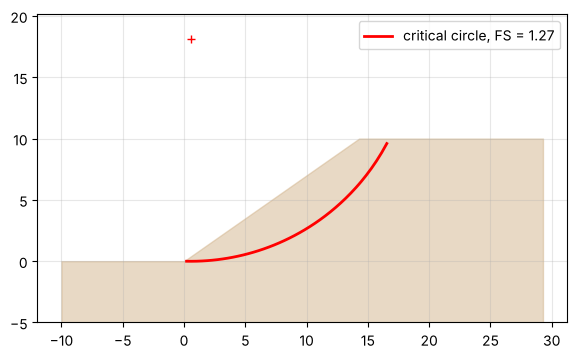

In [7]:
H, beta = 10, 35
res = slopes.critical_circle(H, beta, c=12, phi=28, gamma=19, ru=0.2)
print(f"FS_min = {res['FS']:.3f}  centre = ({res['xc']:.2f}, {res['yc']:.2f}), R = {res['R']:.2f}")
print("Infinite slope (same soil, dry, z = 3 m):", round(slopes.infinite_slope(beta, 28, c=12, gamma=19, z=3), 3))

xcrest = H / np.tan(np.radians(beta))
xg = np.array([-10, 0, xcrest, xcrest + 15]); yg = np.array([0, 0, H, H])
th = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(xg, yg, -5, color="tan", alpha=.5)
sl = res["slices"]
ax.plot(sl["x"], sl["y_base"], "r", lw=2, label=f"critical circle, FS = {res['FS']:.2f}")
ax.plot(res["xc"], res["yc"], "r+")
ax.set_aspect("equal"); ax.set_ylim(-5, res["yc"] + 2); ax.legend(); ax.grid(alpha=.3)
plt.show()

## 7. Pile capacity (API RP 2A)

In [8]:
profile = [{"thickness": 8, "gamma": 17, "gamma_sat": 18, "cu": 40},
           {"thickness": 12, "gamma": 19, "gamma_sat": 20, "sand": 4}]
r = piles.pile_capacity(D=0.6, L=16, layers=profile, water_table=1.0, K=1.0)
print(f"Qs = {r['Qs']:.0f} kN, Qb = {r['Qb']:.0f} kN, Qult = {r['Qult']:.0f} kN, Qadm (FS 2.5) = {r['Qult']/2.5:.0f} kN")
r["table"].round(1)

Qs = 1311 kN, Qb = 1763 kN, Qult = 3074 kN, Qadm (FS 2.5) = 1230 kN


,layer,type,Qs [kN]
0,1,clay,309.3
1,2,sand 4,1002.0
